In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

In [11]:
print(df.shape)
print(df.isna().sum())

(20640, 10)
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [12]:
#These prices were CAPPED by the survey (500001 means "500,001 or more"), so they are not true prices.
print((df["median_house_value"] >= 500001).sum())

965


In [13]:
df = (df[df["median_house_value"] < 500001]).copy()
print(df.shape)

(19675, 10)


- The 965 capped rows force real million-dollar homes to look like $500k properties, which confuses the linear math and drags down the model's prediction slopes.
- Removing them allows your model to accurately predict true, organic values for normal residential homes, but means it can no longer claim to understand or correctly evaluate the luxury real estate market.

In [14]:
df_series = df["median_house_value"]
print("Mean:   ", round(df_series.mean(), 2))
print("Median: ", round(df_series.median(), 2))
print("Std Dev:", round(df_series.std(), 2))
print("Skew:   ", round(df_series.skew(), 2))

Mean:    192477.92
Median:  173800.0
Std Dev: 97711.51
Skew:    0.81


In [17]:
df_corr = df.select_dtypes("number").corr()["median_house_value"]
print(round(df_corr, 3))

longitude            -0.047
latitude             -0.148
housing_median_age    0.068
total_rooms           0.143
total_bedrooms        0.075
population            0.012
households            0.095
median_income         0.643
median_house_value    1.000
Name: median_house_value, dtype: float64


In [18]:
print(df.groupby("ocean_proximity")["median_house_value"].agg(["count", "mean"]))

                 count           mean
ocean_proximity                      
<1H OCEAN         8604  224013.191539
INLAND            6524  123252.620478
ISLAND               5  380440.000000
NEAR BAY          2096  236925.572519
NEAR OCEAN        2446  227716.802944


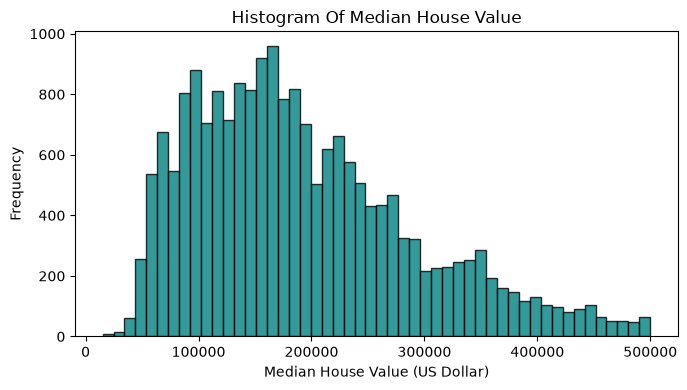

In [25]:
plt.figure(figsize=(7, 4))
plt.hist(df["median_house_value"], bins=50, color="teal", edgecolor="black", alpha=0.8)
plt.title("Histogram Of Median House Value")
plt.xlabel("Median House Value (US Dollar)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

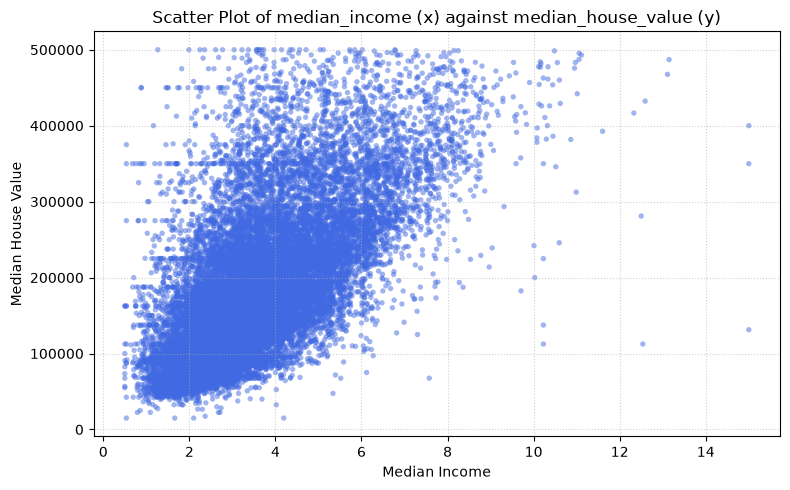

In [24]:
plt.figure(figsize=(8,5))
plt.scatter(df["median_income"], df["median_house_value"], color="royalblue", alpha=0.5, edgecolor="none", s=15)
plt.title("Scatter Plot of median_income (x) against median_house_value (y)")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

1. median_income column is the strongest predictor because it shows how the house prices are actually going based on median income. A positive correlation (0.68) means there is a strong relationship between median_income and median_house_value where if the income of neighbourhoods increase the house prices will also increase.
2. The mean (192,478) is above the median (173,800) tells you that the distribution of home prices are right-skewed.
3. ISLAND group is the cheapest because it suffers from sample size bias where there are only 5 data points for it.

In [43]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

new_cols = ["rooms_per_household", "bedrooms_per_room", "population_per_household"]
ratio_correlations = df.select_dtypes("number").corr()["median_house_value"].loc[new_cols]

print(f"Room Per Household:\n{df["rooms_per_household"].mean()}, {df["rooms_per_household"].max()}\n")
print(f"Bedrooms Per Room:\n{df["bedrooms_per_room"].mean()}, {df['bedrooms_per_room'].max()}\n")
print(f"Population Per Household:\n{df["population_per_household"].mean()}, {df['population_per_household'].max()}\n")
print(f"Correlation with the price: {df.select_dtypes("number").corr()["median_house_value"].loc[new_cols]}")

Room Per Household:
5.360901071712741, 132.53333333333333

Bedrooms Per Room:
0.2149753628994184, 1.0

Population Per Household:
3.0951891178839257, 1243.3333333333333

Correlation with the price: rooms_per_household         0.109673
bedrooms_per_room          -0.215950
population_per_household   -0.021465
Name: median_house_value, dtype: float64


- it is safe to compute these before the split because each new column use its own row. Computing these features across the entire dataset introduces zero risk of information leaking from the future test set into the training set. Every single row remains completely isolated from every other row.

In [44]:
d = pd.get_dummies(df, columns=["ocean_proximity"], dtype=int)
print(d.shape)

(19675, 18)


In [45]:
orig_cols = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "ocean_proximity_<1H OCEAN",
    "ocean_proximity_INLAND", "ocean_proximity_ISLAND", "ocean_proximity_NEAR BAY", "ocean_proximity_NEAR OCEAN"]

eng_cols = orig_cols + ["rooms_per_household", "bedrooms_per_room", "population_per_household"]

print(len(orig_cols), len(eng_cols))

13 16


- Population_per_household has a maximum of 1243.3 while its mean is 3.1. It is probably a typing error because how per household can have more than 1000 people? 

In [47]:
X_all = d[eng_cols]
y = d["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=42) 
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)
print(X_train.shape, X_test.shape)
print(X_tr.shape, X_val.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

(15740, 16) (3935, 16)
(11805, 16) (3935, 16)
192191.086 193625.26


In [48]:
def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:12s} MAE={mae:,.0f}  RMSE={rmse:,.0f}  R2={r2:.4f}")

In [49]:
base = DummyRegressor(strategy="mean")
base.fit(X_tr, y_tr)
report("Baseline:", y_val, base.predict(X_val))

Baseline:    MAE=78,804  RMSE=98,548  R2=-0.0009


- 

In [ ]:
def linear_pipe():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LinearRegression())
    ])

def poly_pipe(degree):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scale", StandardScaler()),
        ("model", LinearRegression()),
    ])

models = {
    "A income":     (linear_pipe(), ["median_income"]),
    "B original":   (linear_pipe(), orig_cols),
    "C engineered": (linear_pipe(), eng_cols),
    "D poly2 eng":  (poly_pipe(2),  eng_cols),
}

for name, (pipe, cols) in models.items():
    pipe.fit(X_tr[cols], y_tr)
    train_r2 = pipe.score(X_tr[cols], y_tr)
    val_r2 = pipe.score(X_val[cols], y_val)
    print(f"{name:14s} train R2={train_r2:.4f}  val R2={val_r2:.4f}")

A income       train R2=0.4124  val R2=0.4069
B original     train R2=0.6104  val R2=0.6187
C engineered   train R2=0.6196  val R2=0.6298
D poly2 eng    train R2=0.7040  val R2=-0.9207


In [54]:
model_d = models["D poly2 eng"][0]
pv = model_d.predict(X_val[eng_cols])
err = (y_val - pv).abs()
print(err.idxmax())
print(X_val.loc[err.idxmax(), "population_per_household"])
print(pv.max())


3364
599.7142857142857
7867200.932154176


- Model C (linear, with the ratio features). Validation R2 0.6298 is
the highest of the four (A 0.4069, B 0.6187, D -0.9207). Its RMSE
(59,931) is also the lowest. We choose on VALIDATION, not on test.

In [55]:
final = linear_pipe()
final.fit(X_train[eng_cols], y_train)
report("Final C", y_test, final.predict(X_test[eng_cols]))
print(final.score(X_train[eng_cols], y_train))
print(final.score(X_test[eng_cols], y_test))

Final C      MAE=45,199  RMSE=61,864  R2=0.6162
0.6224586661765019
0.6161722120615474


- One district has population_per_household = 599.7. PolynomialFeatures
squares it (and multiplies it with the other columns), so the
model's prediction for that row explodes to about 7.87 million
dollars. MAE averages the absolute errors, so that one huge error
adds only about 2,000 to the average over 3,935 rows (about 7.8
million / 3,935). RMSE and R2 SQUARE the errors first, so one huge
error dominates them. Without that single row, D's R2 would be
0.6724, slightly better than C.

In [56]:
pred = final.predict(X_test[eng_cols])
e = y_test - pred
print(e.mean(), np.median(np.abs(e)), np.abs(e).max(), (np.abs(e) < 50000).mean())

200.10023876108747 35824.950164800975 728086.7186695947 0.6533672172808133


In [57]:
print(pred.min(), (pred < 0).sum())

-593686.7186695947 5


In [59]:
res = pd.DataFrame({
    "actual": y_test,                                          # Series
    "pred": pred,                                              # array
    "group": df.loc[X_test.index, "ocean_proximity"],          # Series
})
print(res.shape)           # (3935, 3)
print(res.head(3))
res["abs_error"] = (res["actual"] - res["pred"]).abs()
print(res.groupby("group")["abs_error"].mean().round(0))

(3935, 3)
         actual           pred      group
15065  104200.0  154792.589644  <1H OCEAN
14534  171200.0  214364.117362  <1H OCEAN
13570   97300.0  173939.718505     INLAND
group
<1H OCEAN     46134.0
INLAND        34519.0
ISLAND        93612.0
NEAR BAY      62927.0
NEAR OCEAN    56014.0
Name: abs_error, dtype: float64


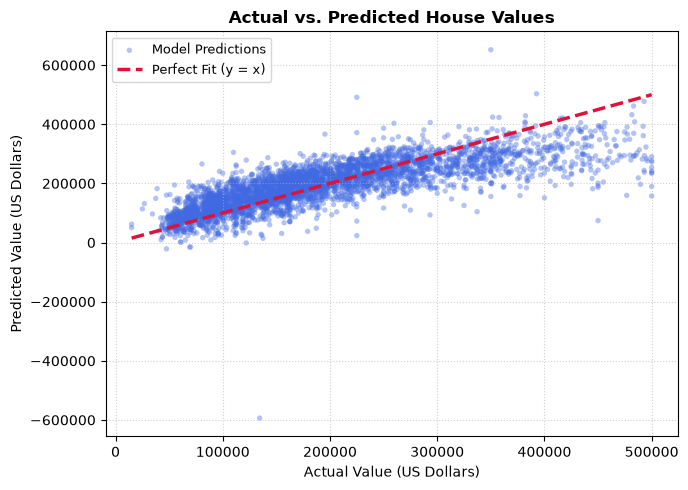

In [62]:
e = y_test - pred
plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred, color="royalblue", alpha=0.4, edgecolors="none", s=15, label="Model Predictions")

min_val, max_val = y_test.min(), y_test.max()
plt.plot([min_val, max_val], [min_val, max_val], color="crimson", linewidth=2.5, linestyle="--", label="Perfect Fit (y = x)")

plt.title("Actual vs. Predicted House Values", fontsize=12, fontweight="bold")
plt.xlabel("Actual Value (US Dollars)", fontsize=10)
plt.ylabel("Predicted Value (US Dollars)", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()


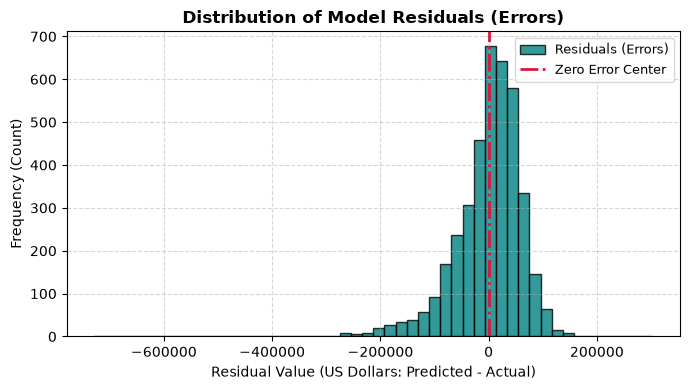

In [61]:
plt.figure(figsize=(7, 4))
plt.hist(e, bins=50, color="teal", edgecolor="black", alpha=0.8, label="Residuals (Errors)")
plt.axvline(x=0, color="crimson", linewidth=2, linestyle="-.", label="Zero Error Center")
plt.title("Distribution of Model Residuals (Errors)", fontsize=12, fontweight="bold")
plt.xlabel("Residual Value (US Dollars: Predicted - Actual)", fontsize=10)
plt.ylabel("Frequency (Count)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [64]:
e = y_test - pred
mae  = np.mean(np.abs(e))
mse  = np.mean(e ** 2)
rmse = np.sqrt(mse)
r2  = 1 - np.sum(e ** 2) / np.sum((y_test - y_test.mean()) ** 2)
print(mae, mse, rmse, r2)

45199.372531582594 3827141429.091846 61863.89438995775 0.6161722120615474


## Conclusion
- The baseline that always predicts the mean has a test MAE of
80,135 dollars. The final linear model with ratio features has MAE
45,199, RMSE 61,864 and R2 0.6162, so it explains about 62% of the
variation in price and cuts the average error by about 35,000
dollars. Median income is the strongest single feature (r = 0.643);
adding the three ratio features improved validation R2 from 0.6187
to 0.6298. I chose model C on VALIDATION R2 and used the test set
once. Model D (degree-2 polynomial) scored -0.92 on validation
because one district with population_per_household = 599.7 was
predicted at about 7.9 million dollars: RMSE and R2 are very
sensitive to one extreme row, while its MAE (41,122) looked fine.
Caveats: the 965 capped rows were removed, so the model says
nothing about houses above 500,000, and a linear model can predict
negative prices (5 cases). Next step: handle extreme ratio values
and try a model that is not a straight line (trees).